# インド株市場の構造とリターンの基本統計

ファクター作りから一歩引いて、MSCI India IMI ユニバース（プロキシ）の **構造**（銘柄数・集中度・セクター・流動性）と
**リターンの性質**（指数の成績、サイズサイクル、分布、個別株の歪み、新規組み入れ銘柄）を定量的に押さえる。
後続のノートブック（02 指数の時系列、03 横断面の状態変数、04 銘柄レベルの時系列、05 ファクターの時系列）の土台になる。

**問い**（インド市場の「構造的な特徴」として事前に予想していること）

1. 集中度は時代とともに下がり、中小型・売買代金が急拡大した（2020 年以降の国内個人・SIP マネー）
2. 中小型（EW）と大型（CW）の差は大きく、何年も続く局面（サイズサイクル）を持つ
3. 指数リターンは負の歪み・厚い裾を持ち、個別株は正の歪み（少数の大化け株）を持つ。Bessembinder（2018）のように、
   富の創出は少数銘柄に集中し、過半の銘柄は指数に負ける
4. 新規上場（IPO）直後の銘柄は、組み入れ後にユニバースを下回る（IPO の長期アンダーパフォーマンス）

**設計・規約**

- データ: `scripts/build_market_panel.py` の共有パネル（`data/market_panel/`）。月末 $t$ のユニバース → 月 $t+1$ の構成。
- 月次リターンは `drtn`（配当込み、INR）。USD 建ては $(1+r_t)\,fx_{t-1}/fx_t - 1$（`data/fx.csv`、1 USD あたり INR）。
- 時価総額は浮動株調整後（`universe.cap`。2007 年以降は USD 百万と推定。値の水準から判断）。
- 指数: `cw_imi`（全銘柄の時価総額加重）、`cw_msci`（大型 + 中型 = MSCI India プロキシ）、`ew_imi`（等ウェイト）、サイズ区分（MSCI の large / mid / small）。
- 日次の指数は価格リターン（配当なし）。分布の分析と新規組み入れ銘柄の分析（ユニバース外に出た後も追うため）に使う。
- 主サンプル: 2008-01〜2026-07（2007 年以前はユニバースが 26〜51 銘柄）。t 値は Newey–West（ラグ 6、月次）。

In [1]:
import sys
from pathlib import Path

import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.insert(0, str(Path("../../scripts").resolve()))
from build_market_panel import SECTOR_NAMES, SIZE_NAMES, load_panel

pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

START, END = "2008-01-31", "2026-07-31"
IS_END = "2017-12-31"
SIZE_COLORS = {"large": "C0", "mid": "C1", "small": "C2"}

panel = load_panel(
    "../../data/market_panel", fields=("close", "ret", "value", "turnover")
)
cap_all = panel.monthly["cap"]
cap = cap_all.loc["2007-12-31":END]  # 月末 t の構成（t+1 に適用）
size = panel.monthly["size"].reindex_like(cap)
sector = panel.monthly["sector"].reindex_like(cap)
drtn = panel.monthly["drtn"].reindex_like(cap)
drtn_usd = panel.monthly["drtn_usd"].reindex_like(cap)
mi = panel.monthly_index.loc[START:END]
di = panel.daily_index.loc["2008-01-01":END]

fx = pd.read_csv("../../data/fx.csv")
fx.index = pd.to_datetime(
    fx["yyyymm"].astype(str), format="%Y%m"
) + pd.offsets.MonthEnd(0)
fx = fx["rate"]


def to_usd(r: pd.DataFrame | pd.Series) -> pd.DataFrame | pd.Series:
    # INR 建て月次リターンを USD 建てに換算する
    g = (fx.shift(1) / fx).reindex(r.index)
    return (1 + r).mul(g, axis=0) - 1


def nw_tstat(x: pd.Series, lags: int = 6) -> float:
    # 平均の Newey–West t 値
    x = pd.Series(x).dropna().to_numpy(dtype=float)
    n = len(x)
    if n < 3:
        return np.nan
    e = x - x.mean()
    s = e @ e / n
    for k in range(1, min(lags, n - 1) + 1):
        s += 2 * (1 - k / (lags + 1)) * (e[k:] @ e[:-k]) / n
    return x.mean() / np.sqrt(s / n)


def month_end_index(idx: pd.DatetimeIndex) -> pd.DatetimeIndex:
    return idx.to_period("M").to_timestamp(how="end").normalize()


print("月数", len(mi), "／ 営業日数", len(di))
print(
    "ユニバース銘柄数（2008-01, 2026-07）:",
    int(cap.loc[START].notna().sum()),
    int(cap.loc[END].notna().sum()),
)

月数 223 ／ 営業日数 4588
ユニバース銘柄数（2008-01, 2026-07）: 249 622


## 1. 構造の推移

左上: サイズ区分別の銘柄数。右上: 上位 10 銘柄のウェイト（IMI と MSCI プロキシ）。左下: 実効銘柄数 $1/\sum_i w_i^2$。
右下: サイズ区分の時価総額ウェイト。いずれも月末時点のユニバース。

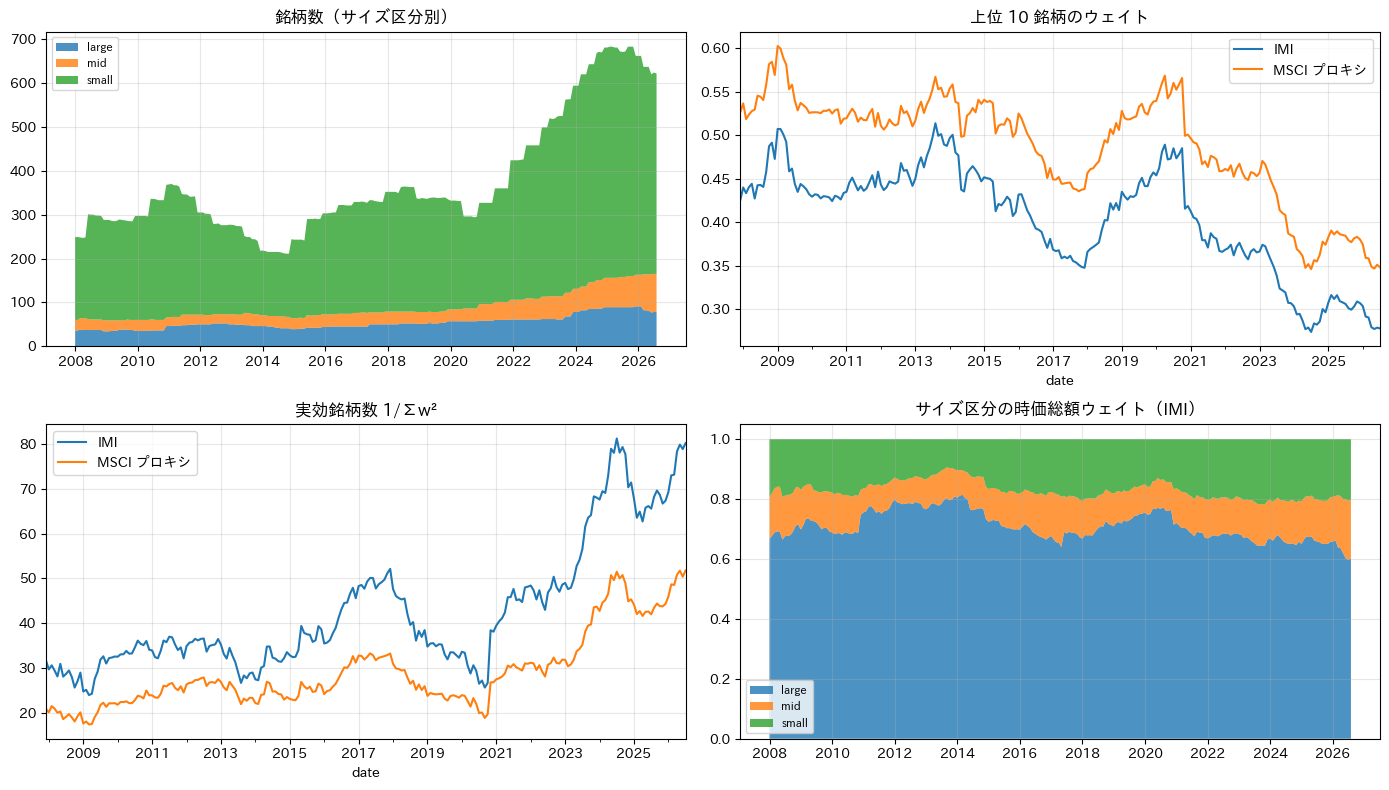

,銘柄数,IMI,MSCI プロキシ,実効 N IMI,実効 N MSCI プロキシ,W large,W mid,W small
date,,,,,,,,
2008-01-31,249,0.440,0.537,29.708,20.131,0.678,0.142,0.180
2012-12-31,277,0.442,0.510,36.498,27.529,0.766,0.100,0.134
2017-12-31,352,0.348,0.438,52.152,33.269,0.668,0.125,0.207
2020-12-31,327,0.419,0.501,38.127,26.842,0.720,0.116,0.164
2023-12-31,594,0.307,0.385,68.054,43.710,0.670,0.128,0.203
2026-07-31,622,0.278,0.348,80.216,51.797,0.602,0.197,0.202


In [2]:
w = cap.div(cap.sum(axis=1), axis=0)
cap_msci = cap.where(size.isin([1, 2]))
wm = cap_msci.div(cap_msci.sum(axis=1), axis=0)

counts = pd.DataFrame({n: (size == k).sum(axis=1) for k, n in SIZE_NAMES.items()})
top10 = pd.DataFrame(
    {
        "IMI": w.apply(lambda r: r.nlargest(10).sum(), axis=1),
        "MSCI プロキシ": wm.apply(lambda r: r.nlargest(10).sum(), axis=1),
    }
)
effn = pd.DataFrame(
    {"IMI": 1 / (w**2).sum(axis=1), "MSCI プロキシ": 1 / (wm**2).sum(axis=1)}
)
size_w = pd.DataFrame(
    {n: w.where(size == k).sum(axis=1) for k, n in SIZE_NAMES.items()}
)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].stackplot(
    counts.index,
    counts.T,
    labels=counts.columns,
    colors=[SIZE_COLORS[c] for c in counts],
    alpha=0.8,
)
axes[0, 0].set_title("銘柄数（サイズ区分別）")
axes[0, 0].legend(loc="upper left", fontsize=8)
top10.plot(ax=axes[0, 1], title="上位 10 銘柄のウェイト")
effn.plot(ax=axes[1, 0], title="実効銘柄数 1/Σw²")
axes[1, 1].stackplot(
    size_w.index,
    size_w.T,
    labels=size_w.columns,
    colors=[SIZE_COLORS[c] for c in size_w],
    alpha=0.8,
)
axes[1, 1].set_title("サイズ区分の時価総額ウェイト（IMI）")
axes[1, 1].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

snap = pd.concat(
    [
        counts.sum(axis=1).rename("銘柄数"),
        top10,
        effn.add_prefix("実効 N "),
        size_w.add_prefix("W "),
    ],
    axis=1,
)
display(
    snap.loc[
        [
            "2008-01-31",
            "2012-12-31",
            "2017-12-31",
            "2020-12-31",
            "2023-12-31",
            "2026-07-31",
        ]
    ].round(3)
)

### セクター構成

IMI の時価総額ウェイト（GICS セクター）。2018 年の GICS 改定（通信サービスの新設）で CommSvc の中身が変わる点に注意。

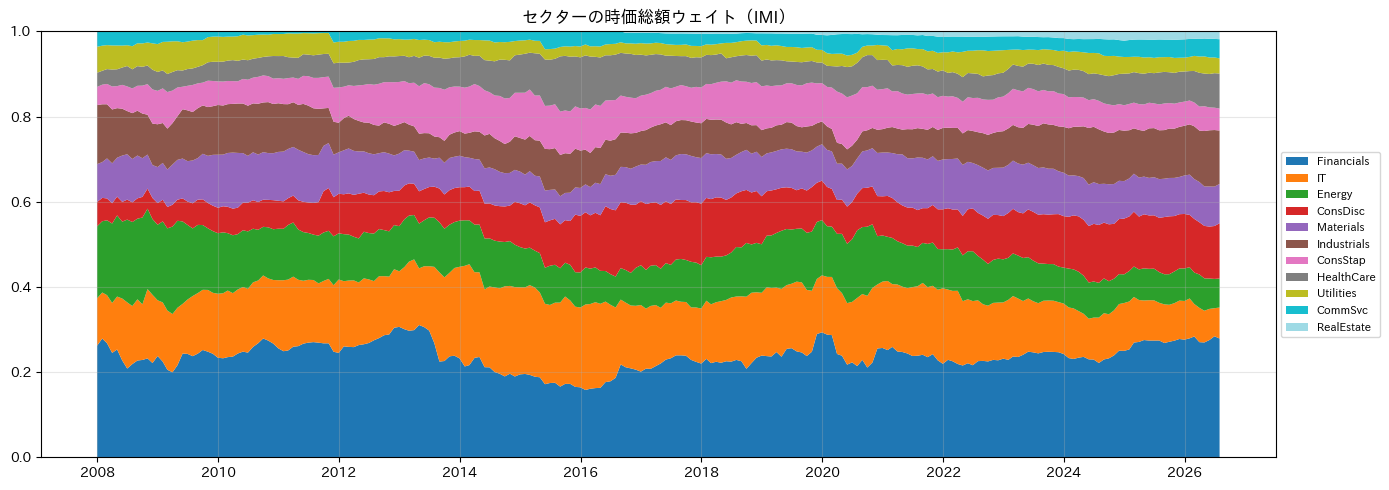

date,2008-01-31,2012-12-31,2017-12-31,2020-12-31,2023-12-31,2026-07-31
Financials,0.279,0.306,0.220,0.257,0.242,0.279
IT,0.108,0.130,0.129,0.156,0.118,0.073
Energy,0.167,0.106,0.102,0.108,0.084,0.068
ConsDisc,0.055,0.083,0.145,0.092,0.121,0.130
Materials,0.084,0.087,0.107,0.103,0.102,0.092
Industrials,0.136,0.069,0.082,0.055,0.108,0.125
ConsStap,0.046,0.099,0.084,0.094,0.077,0.052
HealthCare,0.033,0.061,0.071,0.069,0.060,0.082
Utilities,0.059,0.040,0.026,0.034,0.041,0.036
CommSvc,0.034,0.018,0.030,0.024,0.030,0.045


In [3]:
sec_w = pd.DataFrame(
    {n: w.where(sector == k).sum(axis=1) for k, n in SECTOR_NAMES.items()}
)
order = sec_w.mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(14, 5))
ax.stackplot(
    sec_w.index,
    sec_w[order].T,
    labels=order,
    colors=plt.cm.tab20(np.linspace(0, 1, len(order))),
)
ax.set_ylim(0, 1)
ax.set_title("セクターの時価総額ウェイト（IMI）")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8)
plt.tight_layout()
plt.show()
display(
    sec_w.loc[
        [
            "2008-01-31",
            "2012-12-31",
            "2017-12-31",
            "2020-12-31",
            "2023-12-31",
            "2026-07-31",
        ],
        order,
    ].T.round(3)
)

## 2. 流動性

日次の売買代金（INR、`unadj_close × unadj_volume`）を月次レートで USD に換算。各銘柄の月内中央値をとり、サイズ区分（前月末）ごとの
横断面の中央値を見る。回転率は日次の売買株数 / 発行済株数の月内中央値 × 250（年率）。Amihud は月内の
$\mathrm{mean}(|r_d| / \text{売買代金}_d)$（売買代金は INR 1 億 = 1e7 単位、10 日以上）。

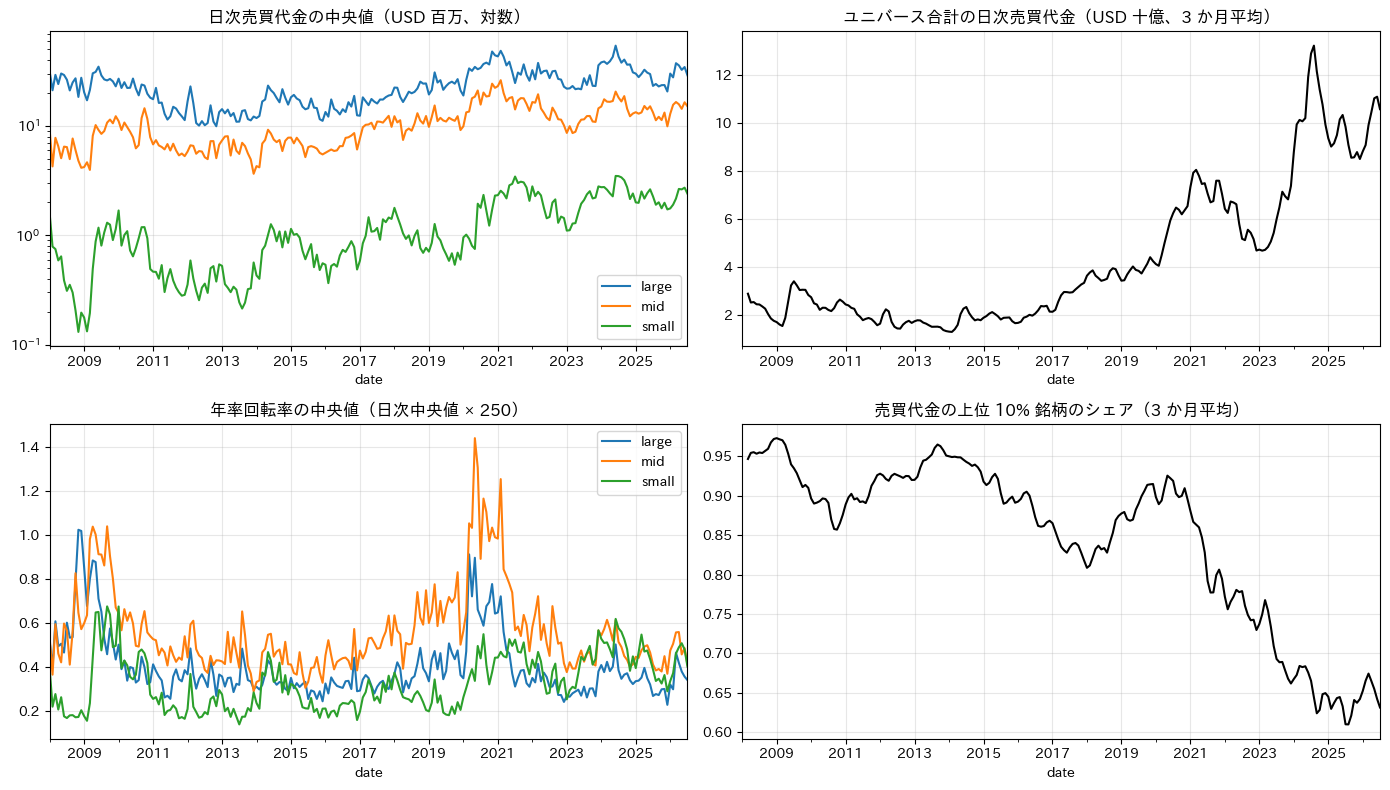

,代金 large,代金 mid,代金 small,回転 large,回転 mid,回転 small,合計代金,上位10%
date,,,,,,,,
2008,25.937,6.108,0.519,0.624,0.546,0.216,2.337,0.957
2009,26.009,8.560,0.793,0.663,0.863,0.470,2.660,0.935
2010,22.682,9.679,0.955,0.384,0.588,0.422,2.392,0.880
2011,14.585,6.269,0.387,0.339,0.469,0.212,1.918,0.905
2012,13.177,6.065,0.404,0.358,0.458,0.228,1.753,0.923
2013,12.606,6.292,0.340,0.346,0.456,0.201,1.546,0.950
2014,17.732,6.967,0.870,0.336,0.454,0.340,1.838,0.941
2015,15.497,6.515,0.768,0.296,0.380,0.239,1.887,0.905
2016,14.528,6.756,0.626,0.325,0.443,0.209,2.092,0.880


In [4]:
mem = panel.member_daily("cap").notna().loc["2008-01-01":END]
days = mem.index
mdays = month_end_index(days)
fx_d = pd.Series(fx.reindex(mdays).to_numpy(), index=days)

val = panel.daily["value"].loc[days].where(mem)
val_usd = val.div(fx_d, axis=0) / 1e6  # USD 百万
to = panel.daily["turnover"].loc[days].where(mem)
ret_d = panel.daily["ret"].loc[days].where(mem)

grp = mdays
mval = val_usd.groupby(grp).median()
mto = to.groupby(grp).median() * 250
illiq_d = ret_d.abs() / (val.where(val > 0) / 1e7)
n_ok = illiq_d.notna().groupby(grp).sum()
amihud = illiq_d.groupby(grp).mean().where(n_ok >= 10)
size_prev = size.shift(1).reindex(mval.index)  # 月 m の構成は前月末のサイズ

med_val = pd.DataFrame(
    {n: mval.where(size_prev == k).median(axis=1) for k, n in SIZE_NAMES.items()}
)
med_to = pd.DataFrame(
    {n: mto.where(size_prev == k).median(axis=1) for k, n in SIZE_NAMES.items()}
)
med_ami = pd.DataFrame(
    {n: amihud.where(size_prev == k).median(axis=1) for k, n in SIZE_NAMES.items()}
)
tot_val = val_usd.sum(axis=1).groupby(grp).mean() / 1e3  # USD 十億 / 日
msum = val_usd.groupby(grp).sum()
top_share = msum.apply(
    lambda r: (
        r.dropna()
        .sort_values(ascending=False)
        .head(max(1, int(np.ceil(0.1 * r.notna().sum()))))
        .sum()
        / r.sum()
    ),
    axis=1,
)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
med_val.plot(
    ax=axes[0, 0],
    logy=True,
    color=[SIZE_COLORS[c] for c in med_val],
    title="日次売買代金の中央値（USD 百万、対数）",
)
tot_val.rolling(3).mean().plot(
    ax=axes[0, 1],
    color="k",
    title="ユニバース合計の日次売買代金（USD 十億、3 か月平均）",
)
med_to.plot(
    ax=axes[1, 0],
    color=[SIZE_COLORS[c] for c in med_to],
    title="年率回転率の中央値（日次中央値 × 250）",
)
top_share.rolling(3).mean().plot(
    ax=axes[1, 1], color="k", title="売買代金の上位 10% 銘柄のシェア（3 か月平均）"
)
plt.tight_layout()
plt.show()

liq_snap = pd.concat(
    [
        med_val.add_prefix("代金 "),
        med_to.add_prefix("回転 "),
        tot_val.rename("合計代金"),
        top_share.rename("上位10%"),
    ],
    axis=1,
)
display(liq_snap.groupby(liq_snap.index.year).mean().round(3))

### Amihud 非流動性

左: サイズ区分別の中央値の推移（対数）。右: 直近 12 か月（2025-08〜2026-07）の銘柄別平均の分布（$\log_{10}$）。

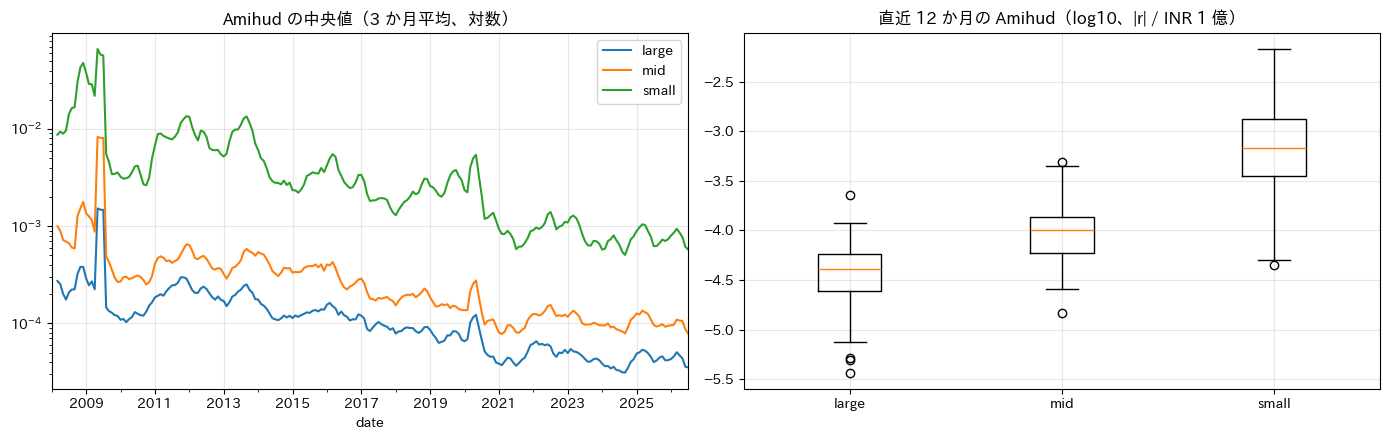

小型 / 大型 の Amihud 中央値の比（年平均）:
date
2008    72.3
2009    54.9
2010    28.7
2011    40.6
2012    36.3
2013    46.2
2014    26.0
2015    23.9
2016    28.2
2017    20.1
2018    25.6
2019    38.5
2020    31.1
2021    17.1
2022    19.6
2023    18.5
2024    18.8
2025    17.3
2026    17.7


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
med_ami.rolling(3).mean().plot(
    ax=axes[0],
    logy=True,
    color=[SIZE_COLORS[c] for c in med_ami],
    title="Amihud の中央値（3 か月平均、対数）",
)
recent = amihud.loc["2025-08-31":END].mean()
sz_last = size.loc[END]
data = [np.log10(recent[sz_last == k].dropna()) for k in SIZE_NAMES]
axes[1].boxplot(data, tick_labels=list(SIZE_NAMES.values()))
axes[1].set_title("直近 12 か月の Amihud（log10、|r| / INR 1 億）")
plt.tight_layout()
plt.show()
ratio = (med_ami["small"] / med_ami["large"]).groupby(med_ami.index.year).mean()
print("小型 / 大型 の Amihud 中央値の比（年平均）:")
print(ratio.round(1).to_string())

## 3. リターンの要約

月次指数（`drtn`、配当込み）。年率リターンは幾何平均、シャープは無リスク金利 0（算術平均 × 12 / 年率ボラ）。
INR 建てと USD 建て。

In [6]:
IDX = ["cw_imi", "cw_msci", "ew_imi", "cw_large", "cw_mid", "cw_small", "ew_small"]
r_inr = mi[IDX]
r_usd = to_usd(r_inr)


def perf(r: pd.DataFrame) -> pd.DataFrame:
    out = {}
    for c in r:
        x = r[c].dropna()
        wealth = (1 + x).cumprod()
        out[c] = {
            "年率リターン": wealth.iloc[-1] ** (12 / len(x)) - 1,
            "年率ボラ": x.std() * np.sqrt(12),
            "シャープ(rf=0)": x.mean() * 12 / (x.std() * np.sqrt(12)),
            "最大DD": (wealth / wealth.cummax() - 1).min(),
            "歪度": stats.skew(x),
            "最悪月": x.min(),
            "月数": len(x),
        }
    return pd.DataFrame(out).T


print("INR 建て（2008-01〜2026-07）")
display(perf(r_inr).round(3))
print("USD 建て")
display(perf(r_usd).round(3))
print("期間別の年率リターン（INR）")
display(
    pd.DataFrame(
        {
            p: perf(r_inr.loc[a:b])["年率リターン"]
            for p, (a, b) in {
                "2008-2012": ("2008", "2012"),
                "2013-2017": ("2013", "2017"),
                "2018-2022": ("2018", "2022"),
                "2023-2026/7": ("2023", "2026"),
            }.items()
        }
    ).round(3)
)

INR 建て（2008-01〜2026-07）


,年率リターン,年率ボラ,シャープ(rf=0),最大DD,歪度,最悪月,月数
cw_imi,0.087,0.214,0.499,-0.550,-0.223,-0.262,223.0
cw_msci,0.084,0.206,0.498,-0.529,-0.237,-0.247,223.0
ew_imi,0.088,0.279,0.442,-0.626,0.468,-0.328,223.0
cw_large,0.082,0.202,0.493,-0.519,-0.257,-0.242,223.0
cw_mid,0.097,0.249,0.496,-0.587,0.081,-0.272,223.0
cw_small,0.099,0.278,0.481,-0.639,0.212,-0.331,223.0
ew_small,0.088,0.296,0.433,-0.644,0.557,-0.340,223.0


USD 建て


,年率リターン,年率ボラ,シャープ(rf=0),最大DD,歪度,最悪月,月数
cw_imi,0.036,0.263,0.268,-0.653,0.085,-0.299,223.0
cw_msci,0.034,0.255,0.259,-0.637,0.053,-0.285,223.0
ew_imi,0.038,0.328,0.274,-0.712,0.699,-0.362,223.0
cw_large,0.032,0.251,0.250,-0.629,0.040,-0.280,223.0
cw_mid,0.046,0.298,0.298,-0.676,0.283,-0.309,223.0
cw_small,0.048,0.325,0.306,-0.722,0.493,-0.364,223.0
ew_small,0.037,0.343,0.276,-0.726,0.781,-0.373,223.0


期間別の年率リターン（INR）


,2008-2012,2013-2017,2018-2022,2023-2026/7
cw_imi,-0.017,0.138,0.112,0.134
cw_msci,-0.009,0.123,0.121,0.118
ew_imi,-0.040,0.180,0.069,0.188
cw_large,-0.011,0.114,0.134,0.103
cw_mid,0.021,0.171,0.043,0.186
cw_small,-0.058,0.225,0.081,0.199
ew_small,-0.052,0.197,0.065,0.190


### 暦年リターン

`ew−cw` は IMI 等ウェイト − 時価総額加重、`small−large` は時価総額加重の小型 − 大型（いずれも暦年リターンの差）。2026 年は 7 月まで。

In [7]:
def yearly(r: pd.DataFrame | pd.Series) -> pd.DataFrame | pd.Series:
    return (1 + r).groupby(r.index.year).prod() - 1


yr = yearly(r_inr)
yr["cw_imi(USD)"] = yearly(r_usd["cw_imi"])
yr["INR/USD 変化"] = yearly(fx.pct_change().loc[START:END])
yr["ew−cw"] = yr["ew_imi"] - yr["cw_imi"]
yr["small−large"] = yr["cw_small"] - yr["cw_large"]
display(
    yr.style.format("{:.1%}").background_gradient(
        cmap="RdYlGn", vmin=-0.6, vmax=0.6, axis=None
    )
)

,cw_imi,cw_msci,ew_imi,cw_large,cw_mid,cw_small,ew_small,cw_imi(USD),INR/USD 変化,ew−cw,small−large
date,,,,,,,,,,,
2008,-58.4%,-56.5%,-64.4%,-55.7%,-60.0%,-66.3%,-66.3%,-66.4%,23.6%,-6.0%,-10.6%
2009,98.0%,94.1%,130.0%,89.4%,128.4%,118.8%,135.1%,107.3%,-4.5%,32.1%,29.5%
2010,16.4%,16.6%,14.5%,17.6%,9.4%,14.6%,15.7%,21.2%,-3.9%,-2.0%,-3.0%
2011,-27.2%,-25.4%,-37.0%,-24.9%,-29.8%,-37.7%,-38.9%,-38.7%,18.8%,-9.8%,-12.9%
2012,31.6%,30.2%,37.9%,27.5%,58.7%,41.3%,36.3%,27.6%,3.2%,6.3%,13.8%
2013,7.5%,9.0%,-5.3%,9.6%,4.9%,-1.1%,-7.9%,-4.8%,12.9%,-12.7%,-10.7%
2014,30.4%,26.6%,50.3%,25.9%,34.2%,61.0%,58.0%,27.8%,2.0%,19.9%,35.1%
2015,-0.3%,-1.9%,1.7%,-2.2%,-1.1%,7.8%,3.8%,-4.9%,4.8%,2.0%,9.9%
2016,1.3%,1.0%,5.0%,0.0%,7.3%,2.0%,4.5%,-1.3%,2.6%,3.7%,2.0%


### 累積リターンとドローダウン（INR、対数目盛）

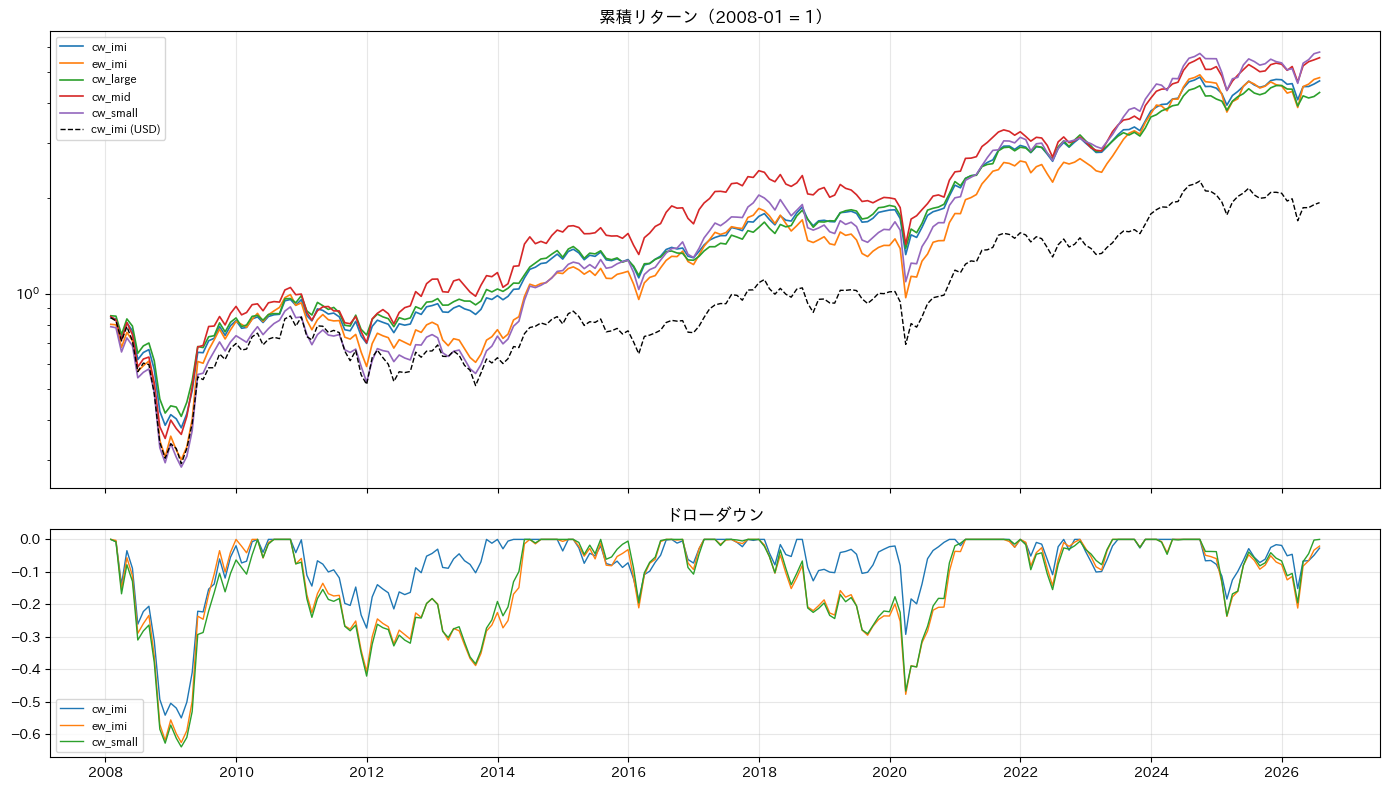

In [8]:
wealth = (1 + r_inr).cumprod()
fig, axes = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)
for c in ["cw_imi", "ew_imi", "cw_large", "cw_mid", "cw_small"]:
    axes[0].plot(wealth.index, wealth[c], label=c, linewidth=1.2)
axes[0].plot(
    wealth.index,
    (1 + r_usd["cw_imi"]).cumprod(),
    label="cw_imi (USD)",
    color="k",
    linestyle="--",
    linewidth=1,
)
axes[0].set_yscale("log")
axes[0].legend(fontsize=8)
axes[0].set_title("累積リターン（2008-01 = 1）")
for c in ["cw_imi", "ew_imi", "cw_small"]:
    dd = wealth[c] / wealth[c].cummax() - 1
    axes[1].plot(dd.index, dd, label=c, linewidth=1)
axes[1].legend(fontsize=8)
axes[1].set_title("ドローダウン")
plt.tight_layout()
plt.show()

### セクターの暦年リターン

セクターの時価総額加重指数（`sec_*`、配当込み）の暦年リターン。上段は素のリターン、表の右端は全期間の年率。

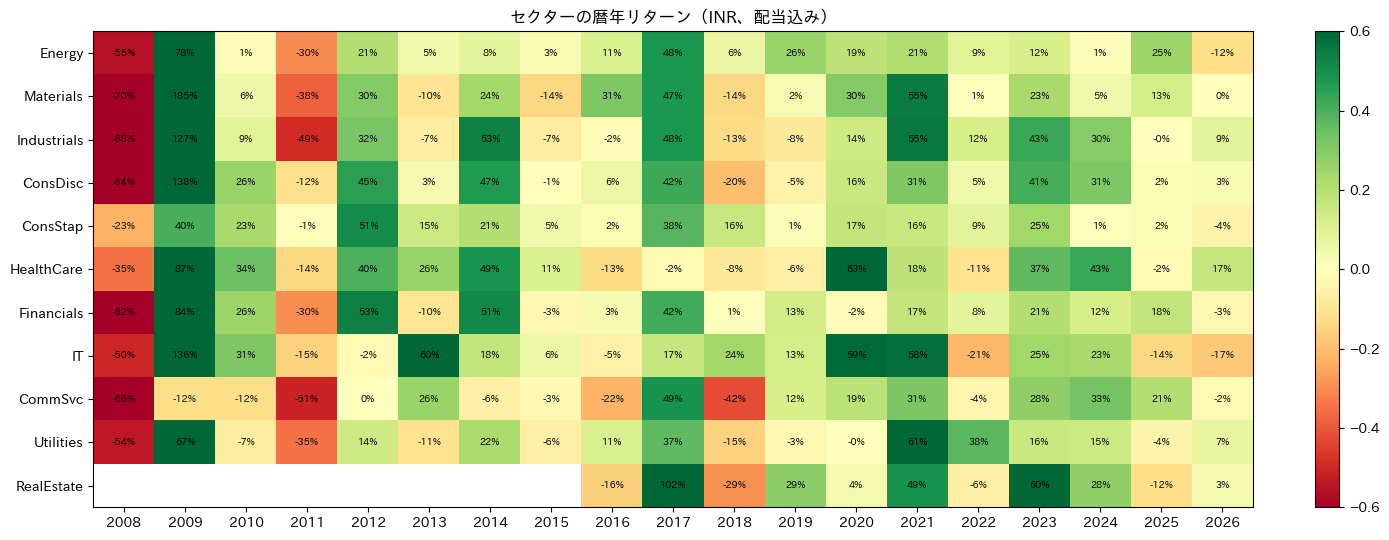

,年率リターン,年率ボラ,シャープ(rf=0)
RealEstate,0.156,0.298,0.642
HealthCare,0.140,0.208,0.739
ConsStap,0.123,0.172,0.764
IT,0.122,0.243,0.599
ConsDisc,0.114,0.250,0.561
Financials,0.078,0.288,0.407
Materials,0.070,0.279,0.382
Energy,0.068,0.256,0.385
Industrials,0.068,0.304,0.366
Utilities,0.040,0.276,0.280


セクター順位の前年との順位相関: 平均 -0.06（年ごと: 2009:-0.38, 2010:+0.52, 2011:+0.73, 2012:+0.53, 2013:-0.24, 2014:-0.41, 2015:-0.31, 2016:-0.53, 2017:-0.16, 2018:-0.55, 2019:+0.07, 2020:-0.14, 2021:-0.03, 2022:+0.04, 2023:-0.36, 2024:+0.65, 2025:-0.24, 2026:-0.32）


In [9]:
sec_cols = [c for c in mi.columns if c.startswith("sec_")]
sec_yr = yearly(mi[sec_cols].dropna(how="all"))
sec_yr.columns = [c.replace("sec_", "") for c in sec_cols]
sec_yr = sec_yr.where(sec_yr != 0)
ann = perf(mi[sec_cols])[["年率リターン", "年率ボラ", "シャープ(rf=0)"]]
ann.index = sec_yr.columns

fig, ax = plt.subplots(figsize=(14, 5.5))
im = ax.imshow(
    sec_yr.T.to_numpy(dtype=float), cmap="RdYlGn", vmin=-0.6, vmax=0.6, aspect="auto"
)
ax.set_xticks(range(len(sec_yr.index)), sec_yr.index)
ax.set_yticks(range(len(sec_yr.columns)), sec_yr.columns)
for i, s in enumerate(sec_yr.columns):
    for j, y in enumerate(sec_yr.index):
        v = sec_yr.loc[y, s]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7)
ax.grid(False)
ax.set_title("セクターの暦年リターン（INR、配当込み）")
plt.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout()
plt.show()
rank_corr = sec_yr.rank(axis=1).T.corr(method="spearman")
lag1 = pd.Series(
    {y: rank_corr.loc[y - 1, y] for y in sec_yr.index[1:] if y - 1 in rank_corr.index}
)
display(ann.sort_values("年率リターン", ascending=False).round(3))
print(
    f"セクター順位の前年との順位相関: 平均 {lag1.mean():.2f}（年ごと: {', '.join(f'{y}:{v:+.2f}' for y, v in lag1.items())}）"
)

### サイズサイクル（EW − CW）

上段: IMI 等ウェイト / 時価総額加重 の累積相対（対数）と、時価総額加重の小型 / 大型。中段: 12 か月の相対リターン。
下段: EW − CW の月次差の自己相関（ラグ 1〜12）。網掛けは 24 か月の相対が負の局面（大型優位）。

時系列の性質として、**過去 12 か月の相対（EW − CW）で翌月・翌 12 か月の相対を説明できるか**（サイズサイクルのモメンタム / 反転）を回帰で見る。
翌 12 か月は重なりのある系列なので Newey–West のラグを 12 にしている。

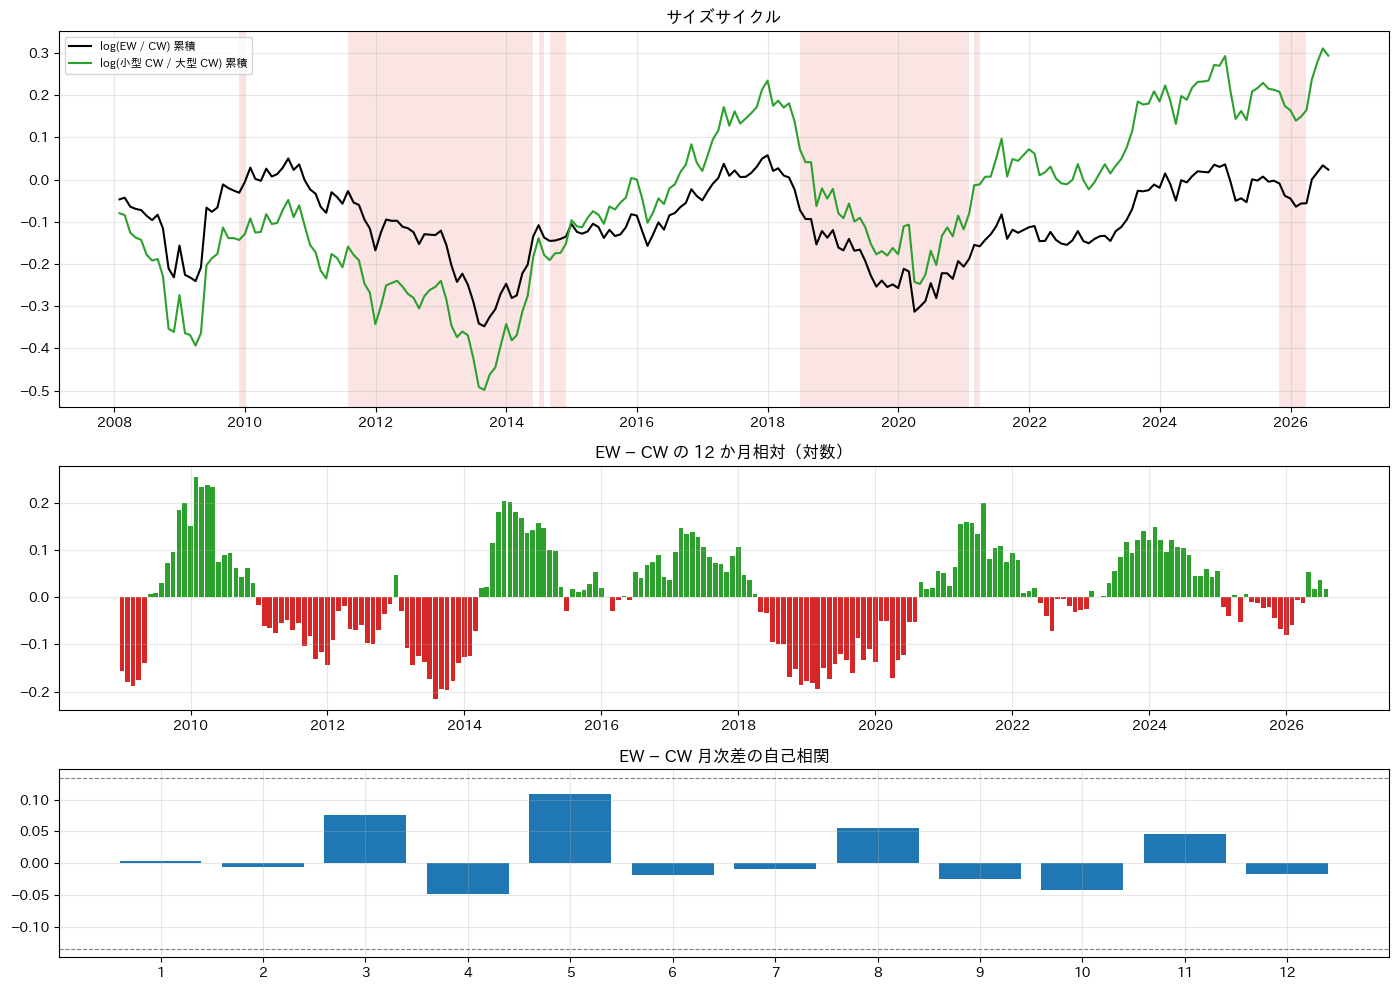

翌期の log(EW/CW) を過去 12 か月の log(EW/CW) に回帰


係数   NW t     R²      n
全期間          翌月     0.010  0.659  0.002  211.0
             翌12か月 -0.140 -0.871  0.021  200.0
IS 2008-2017 翌月     0.003  0.153  0.000  109.0
             翌12か月 -0.290 -1.575  0.088  109.0
OOS 2018-    翌月     0.019  0.949  0.005  102.0
             翌12か月  0.102  0.483  0.012   91.0

EW − CW 月次差の自己相関: 1:+0.00, 2:-0.01, 3:+0.08, 4:-0.05, 5:+0.11, 6:-0.02, 7:-0.01, 8:+0.06, 9:-0.03, 10:-0.04, 11:+0.05, 12:-0.02
EW − CW 月次差: 平均 0.0014（NW t 0.68）、年率ボラ 0.103


In [10]:
spread = (r_inr["ew_imi"] - r_inr["cw_imi"]).rename("ew−cw")
rel = np.log1p(r_inr["ew_imi"]) - np.log1p(r_inr["cw_imi"])
rel_sl = np.log1p(r_inr["cw_small"]) - np.log1p(r_inr["cw_large"])
cum_rel = rel.cumsum()
r12 = rel.rolling(12).sum()
r24 = rel.rolling(24).sum()

acf = pd.Series({k: spread.autocorr(k) for k in range(1, 13)})
fig, axes = plt.subplots(
    3, 1, figsize=(14, 10), gridspec_kw={"height_ratios": [2, 1.3, 1]}
)
axes[0].plot(cum_rel.index, cum_rel, color="k", label="log(EW / CW) 累積")
axes[0].plot(
    rel_sl.index, rel_sl.cumsum(), color="C2", label="log(小型 CW / 大型 CW) 累積"
)
axes[0].legend(fontsize=8)
axes[0].set_title("サイズサイクル")
for d in r24.index[r24 < 0]:
    axes[0].axvspan(d - pd.offsets.MonthEnd(1), d, color="C3", alpha=0.12, linewidth=0)
axes[1].bar(r12.index, r12, width=25, color=np.where(r12 > 0, "C2", "C3"))
axes[1].set_title("EW − CW の 12 か月相対（対数）")
axes[2].bar(acf.index, acf, color="C0")
axes[2].axhline(2 / np.sqrt(len(spread)), color="gray", linestyle="--", linewidth=0.8)
axes[2].axhline(-2 / np.sqrt(len(spread)), color="gray", linestyle="--", linewidth=0.8)
axes[2].set_title("EW − CW 月次差の自己相関")
axes[2].set_xticks(acf.index)
plt.tight_layout()
plt.show()


def ols_nw(y: pd.Series, x: pd.Series, lags: int) -> tuple[float, float, float, int]:
    # y = a + b x の b と NW t 値、R²、n
    d = pd.concat([y, x], axis=1).dropna()
    yy, xx = d.iloc[:, 0].to_numpy(), d.iloc[:, 1].to_numpy()
    X = np.column_stack([np.ones(len(xx)), xx])
    beta = np.linalg.lstsq(X, yy, rcond=None)[0]
    e = yy - X @ beta
    n = len(yy)
    S = (X * e[:, None]).T @ (X * e[:, None]) / n
    for k in range(1, lags + 1):
        G = (X[k:] * e[k:, None]).T @ (X[:-k] * e[:-k, None]) / n
        S += (1 - k / (lags + 1)) * (G + G.T)
    Q = np.linalg.inv(X.T @ X / n)
    V = Q @ S @ Q / n
    r2 = 1 - e.var() / yy.var()
    return beta[1], beta[1] / np.sqrt(V[1, 1]), r2, n


fwd1 = rel.shift(-1)
fwd12 = rel[::-1].rolling(12).sum()[::-1].shift(-1)
rows = {}
for name, (a, b) in {
    "全期間": (START, END),
    "IS 2008-2017": (START, IS_END),
    "OOS 2018-": ("2018-01-31", END),
}.items():
    for h, y, lg in [("翌月", fwd1, 6), ("翌12か月", fwd12, 12)]:
        bb, t, r2, n = ols_nw(y.loc[a:b], r12.loc[a:b], lg)
        rows[(name, h)] = {"係数": bb, "NW t": t, "R²": r2, "n": n}
print("翌期の log(EW/CW) を過去 12 か月の log(EW/CW) に回帰")
display(pd.DataFrame(rows).T.round(3))
print("EW − CW 月次差の自己相関:", ", ".join(f"{k}:{v:+.2f}" for k, v in acf.items()))
print(
    f"EW − CW 月次差: 平均 {spread.mean():.4f}（NW t {nw_tstat(spread):.2f}）、年率ボラ {spread.std() * np.sqrt(12):.3f}"
)

## 4. 分布

指数の日次・週次（金曜締め）・月次の歪度・超過尖度・テール頻度。日次・週次は価格指数（`daily_index`）、月次は配当込み。
「−3σ 超」は平均 − 3 × 標準偏差を下回る頻度（正規分布なら 0.135%）。

n   年率ボラ     歪度    超過尖度  −3σ 超 (%)  +3σ 超 (%)     最小     最大
cw_imi   日次  4588.0  0.202 -0.142  15.080      0.937      0.632 -0.128  0.170
         週次   970.0  0.197 -0.284   5.276      0.722      0.619 -0.180  0.166
         月次   223.0  0.214 -0.223   4.959      1.345      0.448 -0.262  0.320
ew_imi   日次  4588.0  0.210 -0.738   8.805      0.981      0.523 -0.123  0.126
         週次   970.0  0.234  0.087   8.276      0.722      0.412 -0.209  0.281
         月次   223.0  0.279  0.468   8.441      0.897      0.448 -0.328  0.521
cw_small 日次  4588.0  0.210 -0.848   9.223      0.959      0.392 -0.126  0.122
         週次   970.0  0.233 -0.062   8.288      0.619      0.309 -0.219  0.275
         月次   223.0  0.278  0.212   7.920      0.897      0.448 -0.331  0.504

cw_imi の日次下落ワースト 8:
date
2020-03-23   -0.1279
2008-10-24   -0.1063
2008-01-21   -0.0961
2020-03-12   -0.0834
2008-10-10   -0.0794
2009-01-07   -0.0719
2020-03-16   -0.0719
2015-08-24   -0.0660
cw_imi の日次上昇ベスト 5:
date
2009-05-18    0.1697
2020-04-07    0.0817
2008-10-31    0.0797
2008-01-25    0.0718
2008-10-13    0.0667


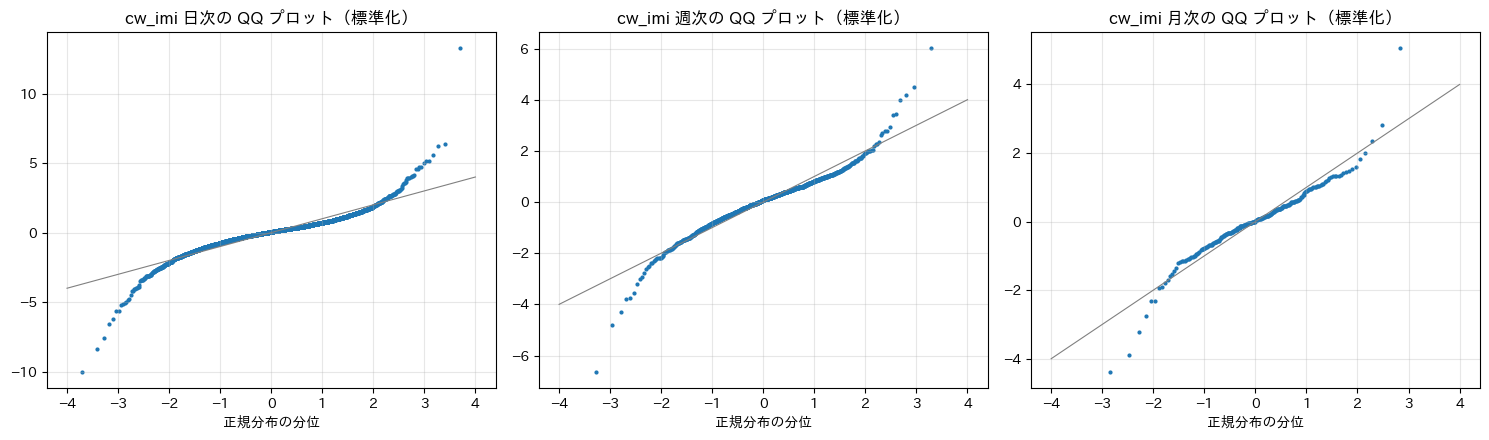

In [11]:
dist_rows = {}
for c in ["cw_imi", "ew_imi", "cw_small"]:
    series = {
        "日次": di[c].dropna(),
        "週次": ((1 + di[c]).resample("W-FRI").prod() - 1).loc[lambda s: s != 0],
        "月次": mi[c].dropna(),
    }
    for f, x in series.items():
        z = (x - x.mean()) / x.std()
        dist_rows[(c, f)] = {
            "n": len(x),
            "年率ボラ": x.std() * np.sqrt({"日次": 250, "週次": 52, "月次": 12}[f]),
            "歪度": stats.skew(x),
            "超過尖度": stats.kurtosis(x),
            "−3σ 超 (%)": (z < -3).mean() * 100,
            "+3σ 超 (%)": (z > 3).mean() * 100,
            "最小": x.min(),
            "最大": x.max(),
        }
display(pd.DataFrame(dist_rows).T.round(3))
print("cw_imi の日次下落ワースト 8:")
print(di["cw_imi"].nsmallest(8).round(4).to_string())
print("cw_imi の日次上昇ベスト 5:")
print(di["cw_imi"].nlargest(5).round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (f, x) in zip(
    axes,
    {
        "日次": di["cw_imi"].dropna(),
        "週次": ((1 + di["cw_imi"]).resample("W-FRI").prod() - 1).loc[lambda s: s != 0],
        "月次": mi["cw_imi"].dropna(),
    }.items(),
):
    z = np.sort(((x - x.mean()) / x.std()).to_numpy())
    q = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
    ax.scatter(q, z, s=4)
    ax.plot([-4, 4], [-4, 4], color="gray", linewidth=0.8)
    ax.set_title(f"cw_imi {f}の QQ プロット（標準化）")
    ax.set_xlabel("正規分布の分位")
plt.tight_layout()
plt.show()

### 個別株の年次リターン

暦年の 12 か月すべてで前月末にユニバース構成銘柄だった銘柄の、`drtn` の複利。指数（`cw_imi`, `ew_imi`）と比べる。

,銘柄数,中央値,平均,cw_imi,ew_imi,cw 超の比率,>+100% の比率,<−50% の比率,歪度
2008,218,-0.69,-0.63,-0.58,-0.64,0.33,0.00,0.78,1.29
2009,251,1.15,1.30,0.98,1.30,0.59,0.57,0.00,0.78
2010,261,0.11,0.14,0.16,0.14,0.44,0.03,0.01,0.59
2011,261,-0.33,-0.29,-0.27,-0.37,0.43,0.00,0.25,1.54
2012,250,0.35,0.44,0.32,0.38,0.54,0.10,0.00,1.67
2013,190,-0.01,0.05,0.07,-0.05,0.41,0.02,0.02,0.85
2014,187,0.43,0.56,0.30,0.50,0.61,0.22,0.01,0.98
2015,218,0.03,0.06,-0.00,0.02,0.54,0.00,0.02,4.21
2016,282,0.01,0.05,0.01,0.05,0.50,0.01,0.02,0.94
2017,303,0.41,0.51,0.35,0.50,0.56,0.13,0.00,1.53


プール（銘柄 × 年 5647）: 中央値 0.090、平均 0.189、歪度 1.74、cw_imi 超の比率の年平均 0.469、平均 − 中央値 0.069


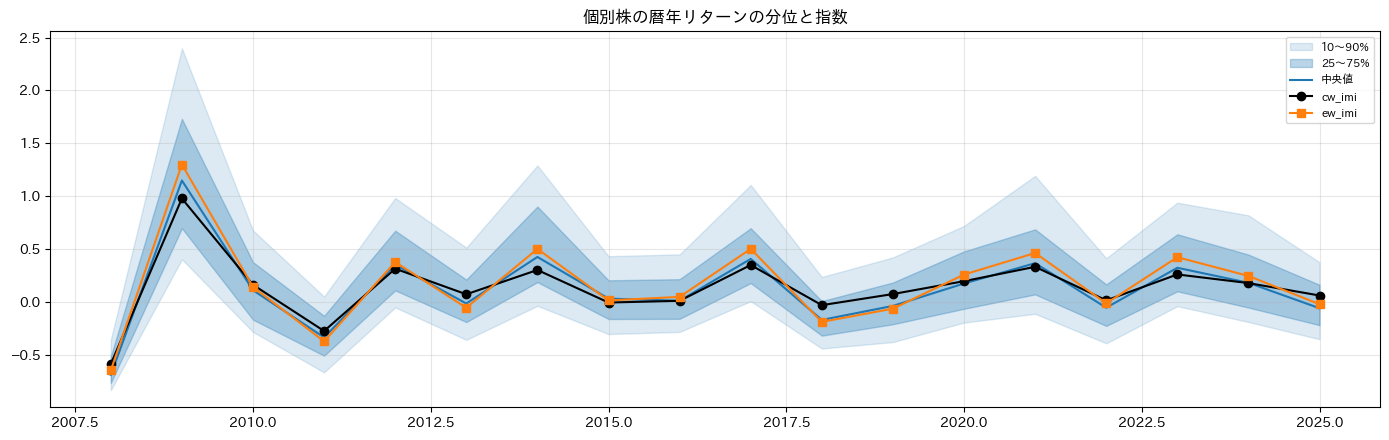

In [12]:
member_prev = cap.shift(1).notna()
r_mem = drtn.where(member_prev).loc[START:END]
cnt_y = r_mem.notna().groupby(r_mem.index.year).sum()
ann_stock = ((1 + r_mem).groupby(r_mem.index.year).prod() - 1).where(cnt_y == 12)
ann_stock = ann_stock.loc[:2025]  # 2026 年は途中なので除く
rows = {}
for y, s in ann_stock.iterrows():
    s = s.dropna()
    rows[y] = {
        "銘柄数": len(s),
        "中央値": s.median(),
        "平均": s.mean(),
        "cw_imi": yr.loc[y, "cw_imi"],
        "ew_imi": yr.loc[y, "ew_imi"],
        "cw 超の比率": (s > yr.loc[y, "cw_imi"]).mean(),
        ">+100% の比率": (s > 1).mean(),
        "<−50% の比率": (s < -0.5).mean(),
        "歪度": stats.skew(s),
    }
ystat = pd.DataFrame(rows).T
display(
    ystat.style.format(
        {c: "{:.0f}" if c == "銘柄数" else "{:.2f}" for c in ystat.columns}
    )
)
pooled = ann_stock.stack()
print(
    f"プール（銘柄 × 年 {len(pooled)}）: 中央値 {pooled.median():.3f}、平均 {pooled.mean():.3f}、歪度 {stats.skew(pooled):.2f}、"
    f"cw_imi 超の比率の年平均 {ystat['cw 超の比率'].mean():.3f}、平均 − 中央値 {ystat['平均'].mean() - ystat['中央値'].mean():.3f}"
)

q = ann_stock.quantile([0.1, 0.25, 0.5, 0.75, 0.9], axis=1).T
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.fill_between(q.index, q[0.1], q[0.9], color="C0", alpha=0.15, label="10〜90%")
ax.fill_between(q.index, q[0.25], q[0.75], color="C0", alpha=0.3, label="25〜75%")
ax.plot(q.index, q[0.5], color="C0", label="中央値")
ax.plot(ystat.index, ystat["cw_imi"], color="k", marker="o", label="cw_imi")
ax.plot(ystat.index, ystat["ew_imi"], color="C1", marker="s", label="ew_imi")
ax.set_title("個別株の暦年リターンの分位と指数")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. 少数の銘柄が富を作るか（Bessembinder 型）

- **保有期間リターン**: 各銘柄について、前月末にユニバース構成だった月の `drtn` を複利でつないだ買い持ちリターン（在籍期間、2008-01〜2026-07）。
  同じ月の `cw_imi` の複利と比べる。
- **富の創出**: $\sum_t \mathrm{cap}_{i,t-1}\, r^{USD}_{i,t}$（USD、無リスク金利は 0）。浮動株調整後の時価総額なので「投資家が取れた分」の近似。
  指数超過版は $r^{USD}_{i,t} - r^{USD}_{\mathrm{cw},t}$。

,銘柄数,在籍月数の中央値,保有期間リターン > 0,cw_imi 超,保有期間リターンの中央値,平均,−50% 以下
全銘柄,1060.0,56.0,0.535,0.366,0.079,2.205,0.230
12 か月以上,941.0,65.0,0.563,0.374,0.210,2.508,0.228
60 か月以上,500.0,127.0,0.686,0.424,0.916,4.547,0.208


富の創出の合計 742（USD 十億）、銘柄数 1060、マイナスの銘柄 53.4%
合計に到達する上位銘柄数: 75（7.1%）


,合計に占める割合
上位 5,0.254
上位 10,0.408
上位 20,0.580
上位 50,0.873
上位 1%（11 銘柄）,0.429
上位 4%（43 銘柄）,0.823
上位 10%（106 銘柄）,1.100


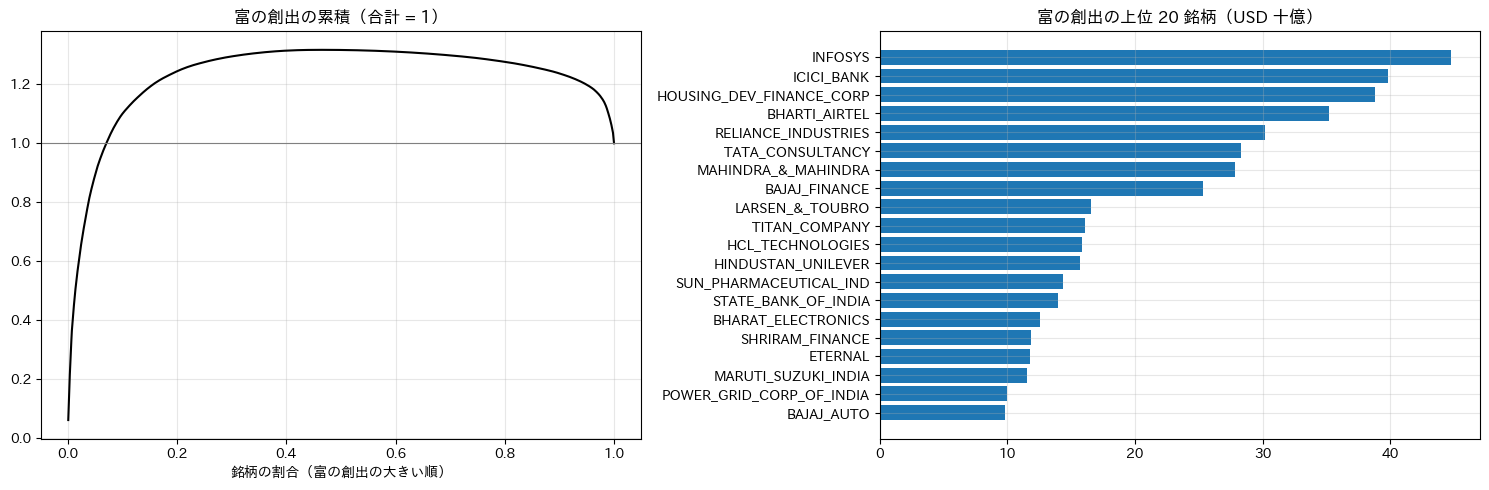

cw_imi 超過の富の創出（時価総額加重なので合計はほぼ 0 = 0.3）: プラスの銘柄 34.1%、プラス分の合計 400 のうち上位 10 銘柄が 32.1%
cw_imi 超過の上位 10: BHARTI_AIRTEL 21, MAHINDRA_&_MAHINDRA 19, ICICI_BANK 19, BAJAJ_FINANCE 12, HOUSING_DEV_FINANCE_ 11, BHARAT_ELECTRONICS 11, ETERNAL 10, TITAN_COMPANY 9, SHRIRAM_FINANCE 9, TVS_MOTOR_CO 8
cw_imi 超過の下位 5: YES_BANK -8, TATA_MOTORS_PASSENGE -13, KOTAK_MAHINDRA_BANK -16, HDFC_BANK -18, RELIANCE_INDUSTRIES -27


In [13]:
names = {}
for p in sorted(Path("../../data/universe").glob("*.pkl")):
    d = pd.read_pickle(p)[["bid", "name"]]
    names.update(dict(zip(d["bid"], d["name"])))

r_life = drtn.where(member_prev).loc[START:END]
cw = r_inr["cw_imi"]
n_m = r_life.notna().sum()
bh = (1 + r_life).prod().where(n_m > 0) - 1
bh_idx = (1 + r_life.notna().mul(cw, axis=0).where(r_life.notna())).prod().where(
    n_m > 0
) - 1
life = pd.DataFrame({"月数": n_m, "保有期間": bh, "同期間の cw_imi": bh_idx}).loc[
    n_m > 0
]
life["超過"] = life["保有期間"] - life["同期間の cw_imi"]
rows = {}
for lab, sub in {
    "全銘柄": life,
    "12 か月以上": life[life["月数"] >= 12],
    "60 か月以上": life[life["月数"] >= 60],
}.items():
    rows[lab] = {
        "銘柄数": len(sub),
        "在籍月数の中央値": sub["月数"].median(),
        "保有期間リターン > 0": (sub["保有期間"] > 0).mean(),
        "cw_imi 超": (sub["超過"] > 0).mean(),
        "保有期間リターンの中央値": sub["保有期間"].median(),
        "平均": sub["保有期間"].mean(),
        "−50% 以下": (sub["保有期間"] < -0.5).mean(),
    }
display(pd.DataFrame(rows).T.round(3))

cap_prev = cap.shift(1).loc[START:END]
r_usd_m = drtn_usd.loc[START:END].where(member_prev.loc[START:END])
cw_usd = r_usd["cw_imi"]
wc = (cap_prev * r_usd_m).sum(min_count=1)
wc_x = (cap_prev * r_usd_m.sub(cw_usd, axis=0)).sum(min_count=1)
wc = wc.dropna().sort_values(ascending=False)
wc_x = wc_x.dropna().sort_values(ascending=False)
tot = wc.sum()
n = len(wc)
top = {f"上位 {k}": wc.head(k).sum() / tot for k in [5, 10, 20, 50]}
top.update(
    {
        f"上位 {p:.0%}（{int(np.ceil(p * n))} 銘柄）": wc.head(
            int(np.ceil(p * n))
        ).sum()
        / tot
        for p in [0.01, 0.04, 0.1]
    }
)
k_all = int((wc.cumsum() >= tot).to_numpy().argmax() + 1)
print(
    f"富の創出の合計 {tot / 1e3:,.0f}（USD 十億）、銘柄数 {n}、マイナスの銘柄 {(wc < 0).mean():.1%}"
)
print(f"合計に到達する上位銘柄数: {k_all}（{k_all / n:.1%}）")
display(pd.Series(top, name="合計に占める割合").round(3).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(
    np.arange(1, n + 1) / n, wc.cumsum() / tot, color="k", label="素の富の創出"
)
axes[0].axhline(1, color="gray", linewidth=0.8)
axes[0].set_xlabel("銘柄の割合（富の創出の大きい順）")
axes[0].set_title("富の創出の累積（合計 = 1）")
t20 = wc.head(20)[::-1] / 1e3
axes[1].barh([names.get(b, b)[:28] for b in t20.index], t20, color="C0")
axes[1].set_title("富の創出の上位 20 銘柄（USD 十億）")
plt.tight_layout()
plt.show()
pos_x = wc_x[wc_x > 0]
print(
    f"cw_imi 超過の富の創出（時価総額加重なので合計はほぼ 0 = {wc_x.sum() / 1e3:,.1f}）: プラスの銘柄 {(wc_x > 0).mean():.1%}、"
    f"プラス分の合計 {pos_x.sum() / 1e3:,.0f} のうち上位 10 銘柄が {pos_x.head(10).sum() / pos_x.sum():.1%}"
)
print(
    "cw_imi 超過の上位 10:",
    ", ".join(
        f"{names.get(b, b)[:20]} {v / 1e3:,.0f}" for b, v in wc_x.head(10).items()
    ),
)
print(
    "cw_imi 超過の下位 5:",
    ", ".join(
        f"{names.get(b, b)[:20]} {v / 1e3:,.0f}" for b, v in wc_x.tail(5).items()
    ),
)

## 6. 新規組み入れ銘柄（IPO 近似）のその後

- イベント: ユニバースに初めて現れた月末 $t_0$（2009-01〜。2007 年のユニバース拡大の影響を避ける）。
- **短い履歴**: $t_0$ 時点の日次株価の履歴が 12 か月未満（≒ 上場から 1 年以内の組み入れ、IPO 近似）。それ以外は「既存上場」。
- リターン: 日次の価格リターンを月次に複利（配当なし）。ユニバースから外れた後も株価があれば追う（生存バイアスを避ける）。
  基準は日次の `ew_imi` を月次に複利したもの（同じく価格）。
- **イベント時間**: $k = -12 \ldots 24$ か月の平均超過リターンの累積（$k \le 0$ は組み入れ前で、組み入れを知っている事後の記述）。
- **カレンダー時間**: 各月、組み入れ後 1〜12 か月（または 13〜24 か月）の銘柄の等ウェイト − 基準。月次の平均と NW t 値。実行可能なポートフォリオ。

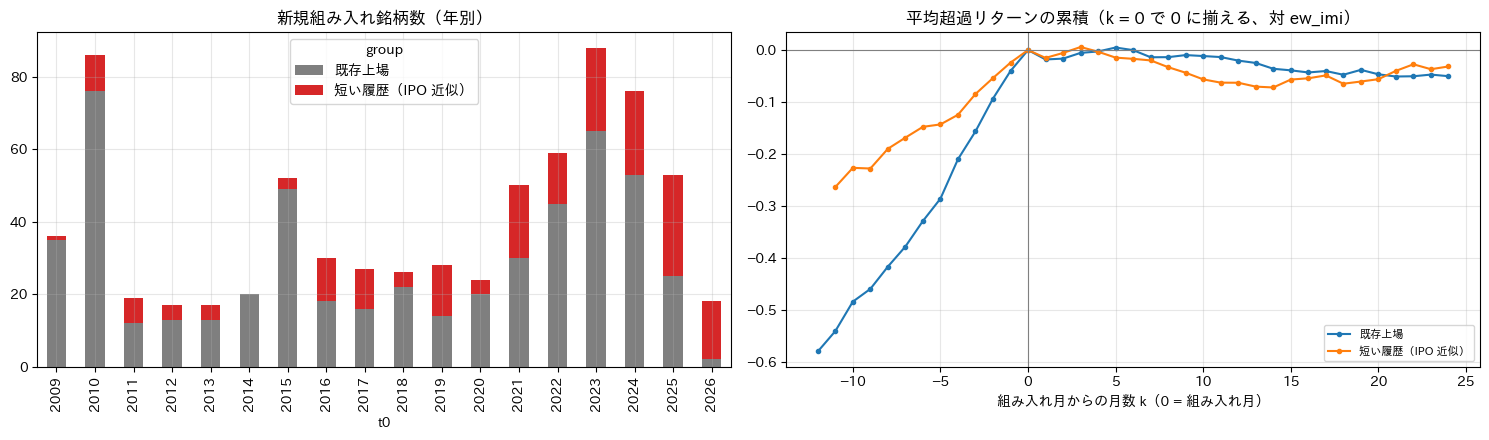

組み入れ前 12 か月（k = −11..0）の累積超過: {'既存上場': 0.581, '短い履歴（IPO 近似）': 0.163}
組み入れ後の累積超過（k = 1..6, 12, 24）:


,既存上場,短い履歴（IPO 近似）
1,-0.018,-0.015
3,-0.005,0.006
6,-0.000,-0.017
12,-0.020,-0.063
18,-0.048,-0.065
24,-0.050,-0.032


カレンダー時間ポートフォリオ（等ウェイト − ew_imi、5 銘柄以上の月）


月平均      年率    NW t     月数
既存上場         1〜12 か月  全期間       -0.0056 -0.0677 -1.7986  206.0
                      IS -2017  -0.0116 -0.1394 -2.0977  103.0
                      OOS 2018-  0.0003  0.0041  0.1648  103.0
             13〜24 か月 全期間       -0.0036 -0.0431 -1.9130  194.0
                      IS -2017  -0.0045 -0.0539 -1.5780   91.0
                      OOS 2018- -0.0028 -0.0336 -1.1370  103.0
短い履歴（IPO 近似） 1〜12 か月  全期間       -0.0042 -0.0499 -1.6842  138.0
                      IS -2017  -0.0051 -0.0616 -1.6162   43.0
                      OOS 2018- -0.0037 -0.0447 -1.1276   95.0
             13〜24 か月 全期間        0.0032  0.0388  0.8171  126.0
                      IS -2017   0.0175  0.2102  1.9624   31.0
                      OOS 2018- -0.0014 -0.0171 -0.4163   95.0

In [14]:
first = cap_all.notna().idxmax()
first_close = panel.daily["close"].notna().idxmax()
ev = pd.DataFrame({"t0": first, "first_close": first_close})
ev = ev[(ev["t0"] >= "2009-01-31") & (ev["t0"] <= END)]
ev = ev.loc[
    ev.index.intersection(panel.daily["ret"].columns)
]  # 日次株価のない銘柄を除く
ev["hist_m"] = (ev["t0"] - ev["first_close"]).dt.days / 30.44
ev["group"] = np.where(ev["hist_m"] < 12, "短い履歴（IPO 近似）", "既存上場")

ret_all = panel.daily["ret"].loc["2007-01-01":END]
valid = ret_all.notna().groupby(month_end_index(ret_all.index)).sum()
mret = (
    (1 + ret_all.fillna(0)).groupby(month_end_index(ret_all.index)).prod() - 1
).where(valid > 0)
bench = (1 + panel.daily_index["ew_imi"].loc["2007-01-01":END]).groupby(
    month_end_index(panel.daily_index.loc["2007-01-01":END].index)
).prod() - 1
xret = mret.sub(bench, axis=0)

cnt_ev = ev.groupby([ev["t0"].dt.year, "group"]).size().unstack(fill_value=0)
months = xret.index
pos = pd.Series(np.arange(len(months)), index=months)
K = range(-12, 25)
car = {}
for g, sub in ev.groupby("group"):
    mat = pd.DataFrame(np.nan, index=sub.index, columns=list(K))
    for b, row in sub.iterrows():
        i0 = pos[row["t0"]]
        for k in K:
            if 0 <= i0 + k < len(months):
                mat.loc[b, k] = xret.iloc[i0 + k][b]
    car[g] = mat
car_mean = pd.DataFrame({g: m.mean() for g, m in car.items()})
car_cum = car_mean.loc[1:].cumsum()
pre = car_mean.loc[-11:0].sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
cnt_ev.plot.bar(
    stacked=True, ax=axes[0], color=["C7", "C3"], title="新規組み入れ銘柄数（年別）"
)
for g in car_mean:
    full = car_mean[g].cumsum() - car_mean[g].loc[:0].sum()
    axes[1].plot(full.index, full, marker=".", label=g)
axes[1].axvline(0, color="gray", linewidth=0.8)
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_xlabel("組み入れ月からの月数 k（0 = 組み入れ月）")
axes[1].set_title("平均超過リターンの累積（k = 0 で 0 に揃える、対 ew_imi）")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("組み入れ前 12 か月（k = −11..0）の累積超過:", pre.round(3).to_dict())
print("組み入れ後の累積超過（k = 1..6, 12, 24）:")
display(car_cum.loc[[1, 3, 6, 12, 18, 24]].round(3))

# カレンダー時間
ev_pos = ev["t0"].map(pos)
rows = {}
port = {}
for g, sub in ev.groupby("group"):
    for lo, hi in [(1, 12), (13, 24)]:
        r = {}
        for m in months[months >= "2009-02-28"]:
            i = pos[m]
            age = i - ev_pos.loc[sub.index]
            held = age[(age >= lo) & (age <= hi)].index
            x = xret.loc[m, held].dropna()
            if len(x) >= 5:
                r[m] = x.mean()
        s = pd.Series(r)
        port[(g, f"{lo}-{hi}")] = s
        for per, (a, b) in {
            "全期間": ("2009", END),
            "IS -2017": ("2009", IS_END),
            "OOS 2018-": ("2018", END),
        }.items():
            ss = s.loc[a:b]
            rows[(g, f"{lo}〜{hi} か月", per)] = {
                "月平均": ss.mean(),
                "年率": ss.mean() * 12,
                "NW t": nw_tstat(ss),
                "月数": len(ss),
            }
print("カレンダー時間ポートフォリオ（等ウェイト − ew_imi、5 銘柄以上の月）")
display(pd.DataFrame(rows).T.round(4))

### 短い履歴の銘柄: 時期別

IPO の波（2010、2017〜18、2021〜24）ごとに、組み入れ後 12 か月の累積超過（イベント時間、銘柄平均）を見る。

In [15]:
m = car["短い履歴（IPO 近似）"]
c12 = m.loc[:, 1:12].sum(axis=1, min_count=6)
by_year = pd.DataFrame(
    {
        "銘柄数": c12.groupby(ev.loc[m.index, "t0"].dt.year).count(),
        "12か月累積超過の平均": c12.groupby(ev.loc[m.index, "t0"].dt.year).mean(),
        "中央値": c12.groupby(ev.loc[m.index, "t0"].dt.year).median(),
    }
)
display(by_year.round(3))
m2 = car["既存上場"]
c12b = m2.loc[:, 1:12].sum(axis=1, min_count=6)
print(
    f"短い履歴: 平均 {c12.mean():.3f}、中央値 {c12.median():.3f}、勝率 {(c12 > 0).mean():.2f}（n={c12.count()}）"
)
print(
    f"既存上場: 平均 {c12b.mean():.3f}、中央値 {c12b.median():.3f}、勝率 {(c12b > 0).mean():.2f}（n={c12b.count()}）"
)

,銘柄数,12か月累積超過の平均,中央値
t0,,,
2009,1,-1.841,-1.841
2010,10,0.010,-0.004
2011,7,-0.070,0.079
2012,4,-0.446,-0.395
2013,4,0.128,-0.053
2015,3,0.029,0.107
2016,12,0.013,-0.024
2017,11,-0.106,-0.234
2018,4,0.417,0.254


短い履歴: 平均 -0.063、中央値 -0.065、勝率 0.38（n=182）
既存上場: 平均 -0.021、中央値 -0.014、勝率 0.49（n=525）


## 所見

**結論: インド株は 2020 年以降、銘柄数・流動性・分散の面で「別の市場」に変わった。リターンは時価総額加重と等ウェイトでほぼ同じ年率（8.7% vs 8.8%）だが、
両者の差（サイズサイクル）は年 ±15〜30% の大きな波を持ち、しかも自分自身の過去からは予測できない。個別株は強い正の歪みを持ち、
同期間の指数に勝つのは 37% だけで、正味の富の創出は上位 7%（75 銘柄）で全部説明できる。新規組み入れ銘柄は組み入れ後にユニバースをやや下回るが、有意性は弱い。**

1. **構造（集中の緩和）**: 銘柄数は 249（2008-01）→ 622（2026-07、ピークは 2024〜25 年の約 680）。上位 10 銘柄ウェイトは IMI 44% → 28%、MSCI プロキシ 54% → 35%、
   実効銘柄数は IMI 30 → 80、MSCI プロキシ 20 → 52。ただし一方向ではなく、2018〜2020 年に再集中（IMI 上位 10 が 49%、実効 N 26）した後、2021 年以降に急速に分散した。
   サイズ区分の時価総額ウェイトは大型 68% → 60%、中型 14% → 20%。セクターは金融が 22〜31% で常に最大、エネルギー 17% → 7%、IT 11%（2020 年 16%）→ 7% と縮小し、
   一般消費財 6% → 13%、資本財 14% →（2020 年 6%）→ 13%、ヘルスケア 3% → 8% が拡大した。
2. **流動性（中小型の投資可能性が構造的に改善）**: ユニバース合計の日次売買代金は USD 2.3bn（2008）→ 1.5bn（2013 年の底）→ 11.0bn（2024）→ 10.4bn（2026）。
   小型株の日次売買代金の中央値は USD 0.5m → 2.1〜2.8m（2024〜26）と 4〜5 倍になった一方、大型株は 26m → 27〜40m とほぼ横ばい。
   売買代金の上位 10% 銘柄のシェアは 96% → 65%、Amihud の小型 / 大型の比は 72 倍 → 17 倍、小型の年率回転率（中央値）は 0.22 → 0.40〜0.50 で大型（0.3〜0.4）を上回った。
3. **指数の成績（INR、2008-01〜2026-07）**: `cw_imi` 年率 8.7%、ボラ 21.4%、シャープ 0.50、最大 DD −55%。`ew_imi` 8.8%、27.9%、0.44、−63%。大型 8.2%、中型 9.7%、小型 9.9%（CW）。
   USD 建てでは `cw_imi` 3.6%（INR は年約 5% 減価、2008 年は単年で −24%）。期間別の EW − CW 年率は 2008〜12 年 −2.3%、2013〜17 年 +4.2%、2018〜22 年 −4.3%、2023〜26 年 +5.4%。
4. **サイズサイクル**: EW − CW の月次差は平均 +0.14%（NW t 0.68）、年率ボラ 10.3%。暦年では 2009 年 +32%、2014 年 +20%、2017 年 +15%、2023 年 +16% と、
   2013 年 −13%、2018 年 −16%、2019 年 −14%、2025 年 −8% が交互に来る（2〜4 年の波）。それでも月次差の自己相関はラグ 1〜12 ですべて |ρ| ≤ 0.11（2 標準誤差内）で、
   過去 12 か月の相対で翌月（係数 0.010、t 0.66）も翌 12 か月（−0.14、t −0.87。IS −1.58 / OOS +0.48）も予測できない。**波は大きいが、自分の過去からは時機を読めない。**
5. **セクター（ディフェンシブが高シャープ）**: 年率は不動産 15.6%、ヘルスケア 14.0%、生活必需品 12.3%、IT 12.2%、一般消費財 11.4% に対し、金融 7.8%、素材 7.0%、
   エネルギー 6.8%、資本財 6.8%、公益 4.0%、通信 −5.6%。シャープは生活必需品 0.76・ヘルスケア 0.74 に対し、景気敏感（素材・エネルギー・資本財・金融）は 0.37〜0.41。
   暦年のセクター順位の前年との順位相関は平均 −0.06（年により −0.55〜+0.73）で、**年単位のセクターモメンタムは平均的には無い**（1 か月の業種モメンタムが効くという `industry_factor/01` とは時間軸が違う）。
6. **分布**: `cw_imi` の日次は超過尖度 15、−3σ 超の頻度 0.94%（正規分布の 7 倍）。最悪日は 2020-03-23（−12.8%）、2008-10-24（−10.6%）。
   等ウェイト・小型は**日次では負の歪み（−0.74、−0.85）だが月次では正の歪み（+0.47、+0.21）**に反転する。暴落日は一斉に下がるが、月単位では大きな反発が右裾を作る。
7. **個別株の歪み**: 銘柄 × 年（5,647）の年次リターンは中央値 9.0%、平均 18.9%、歪度 1.74。各年に `cw_imi` に勝った銘柄の比率は平均 47%。
   比率が低い「狭い相場」は 2018 年 29%、2008 年 33%、2025 年 34%、2019 年 35% で、いずれも EW < CW の年と一致する。
8. **Bessembinder 型**: 在籍期間の買い持ちリターンがプラスの銘柄は 54%、同じ月の `cw_imi` に勝ったのは 37%（60 か月以上在籍でも 42%）。中央値 7.9% に対し平均 220%。
   富の創出（浮動株時価総額 × USD リターン、無リスク金利 0、名目）は合計 USD 742bn で、53% の銘柄はマイナス。上位 5 銘柄で 25%、上位 10 銘柄で 41%、上位 1%（11 銘柄）で 43%、
   **上位 75 銘柄（7.1%）で正味の全部**（米国の Bessembinder の「4% で全部」と同じ桁）。指数超過で見ても勝ち銘柄は 34%（Bharti Airtel、M&M、ICICI Bank、Bajaj Finance が上位、
   Reliance、HDFC Bank、Kotak Mahindra Bank が下位。HDFC の合併・Tata Motors の分割の影響を含む）。
9. **新規組み入れ銘柄**（2009〜2026 年に 707 件、うち履歴 12 か月未満の IPO 近似 182 件。2021〜25 年は年 14〜28 件の IPO 近似）:
   - 既存上場の銘柄は組み入れ前 12 か月に ew_imi 比 +58% 上がってから入る（時価総額の基準を超えたから入る、という機械的な関係）。
   - カレンダー時間（組み入れ後 1〜12 か月、等ウェイト − ew_imi）: 既存上場 −6.8%/年（NW t −1.80。IS −13.9%・t −2.10、OOS +0.4%・t 0.16）、IPO 近似 −5.0%/年（t −1.68。IS t −1.62、OOS t −1.13）。
     13〜24 か月は既存上場 −4.3%（t −1.91）、IPO 近似 +3.9%（t 0.82）。
   - イベント時間の 12 か月累積超過は IPO 近似 −6.3%（中央値 −6.5%、勝率 38%）、既存上場 −2.0%（中央値 −1.4%、勝率 49%）。
   - 方向は「組み入れ後に負ける」でそろうが、12 本の検定のうち |t| > 2 は IS の 1 本だけで、OOS では弱い。IPO 近似は IS・OOS とも負だが有意ではない。

**含意**

- **評価の母集団が時代で変わる**: 2021 年以降に銘柄数が倍になり、増えたのは小型と新規上場。等ウェイトの分位分析は、近年ほど「小型・新規上場の多い母集団」を見ている。
  ファクターの IC や Q5−Q1 を期間比較するときは、サイズ区分内や銘柄数を固定した母集団でも確認したい。
- **流動性・サイズのプレミアムは過去と同じとは限らない**: 小型の流動性は 4〜5 倍、Amihud の格差は 1/4 に縮んだ。過去の非流動性プレミアム（Barra LIQUIDTY −1.8%/年）は
  流動性の低かった時代の値で、取引コストの前提も時代で変えるべき。逆に、小型を実際に運用できる余地は広がっている。
- **等ウェイトの Q5 には構造的な不利がある**: 個別株は正の歪みが強く、中央値の銘柄は指数に負ける（勝つのは年平均 47%、生涯では 37%）。
  Q5 − BM が負ける年は「狭い相場」（勝つ銘柄が 3 割前後）と重なり、`healthy_compounder/03` の 2018〜19 年の結論（構造の負け）と同じ現象が 2025 年にも出ている。
- **サイズサイクルを時機で取るなら外部の状態変数が要る**: 自己相関もモメンタムも無いので、資金フロー・バリュエーション格差・相場の広がり（勝つ銘柄の比率、集中度の変化）などを使う必要がある（03 の範囲）。
- **セクターのディフェンシブ性**: 生活必需品・ヘルスケアの高いシャープは、低ボラ系のファクター（`vola60` など）の成績がセクター配分から来ている可能性を示す。

**次の候補（アイディア）**

1. **上場・組み入れからの経過月数**（IPO 直後と組み入れ直後のペナルティ）: 新しいシグナル。`core` の `availm12` / `availm60`（データの存在月数と思われる）との重複を先に確認する。
   組み入れ前の +58% の急騰はモメンタムのスコアを押し上げるので、「モメンタム × 組み入れ直後」の交互作用（組み入れ直後はモメンタムを割り引く）も候補。根拠は弱め（t −1.7〜−2.1、OOS で弱い）。
2. **相場の広がりの指標**（`cw_imi` に勝つ銘柄の比率、上位 10 銘柄ウェイトの 6〜12 か月変化）を、サイズサイクルと Q5 − BM の構造リスクの状態変数として 03 で検証する。
   「狭い相場」に入ったときに bax の SIZE 制約を締めるなど、ロングオンリーの構造リスクの管理に使える。
3. **取引コストと流動性の時代依存**: 小型株のコスト・容量の前提を、Amihud や売買代金の推移に合わせて時変にする（評価の精度向上。シグナルではない）。
4. **低ボラ・クオリティのセクター中立版の確認**: ディフェンシブ・セクターの高シャープが、低ボラ系ファクターの成績のどれだけを占めるかを、業種内 / 業種間の分解（`alphaeval.industry`）で確かめる。

注意: 富の創出は名目 USD・無リスク金利 0 で、Bessembinder（T-bill 超過）とは定義が違う。時価総額は浮動株調整後で、単位（USD 百万）は値の水準から推定した。
新規組み入れの分析は価格リターン（配当なし）で、日次株価の無い銘柄は除いた。t 値は Newey–West（ラグ 6、翌 12 か月の回帰はラグ 12）で、多重検定の補正はしていない。